<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U2_2_eda_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 2.2: Transformation, EDA and Split

- **Registration number:** COM/0019/23
- **owner:** Raphael Wanyama (Member 2)
- **Module:** 3

**Contents**
1. Dataset loading
2. Data transformation
3. Exploratory data analysis (EDA)
4. Data scaling
5. Train-test split
6. Written answer

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
# Import the libraries and load the cleaned data from Task 2.1
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/CSC4110_G01/data/stage1_students.csv")

# Work on a copy so the loaded table stays unchanged
df_clean = df.copy()

In [15]:
# Five columns share the same Low/Medium/High order
low_med_high = {'Low': 0, 'Medium': 1, 'High': 2}
for col in ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
            'Family_Income', 'Teacher_Quality']:
    df_clean[col] = df_clean[col].map(low_med_high)

# Three columns have their own orderings
df_clean['Parental_Education_Level'] = df_clean['Parental_Education_Level'].map(
    {'High School': 0, 'College': 1, 'Postgraduate': 2})
df_clean['Distance_from_Home'] = df_clean['Distance_from_Home'].map(
    {'Near': 0, 'Moderate': 1, 'Far': 2})
df_clean['Peer_Influence'] = df_clean['Peer_Influence'].map(
    {'Negative': 0, 'Neutral': 1, 'Positive': 2})

In [16]:
# Convert the three Yes/No columns to 1/0
yes_no = {'Yes': 1, 'No': 0}
for col in ['Extracurricular_Activities', 'Internet_Access', 'Learning_Disabilities']:
    df_clean[col] = df_clean[col].map(yes_no)

# One-hot encode the two unordered columns (creates one 0/1 column per label)
df_clean = pd.get_dummies(df_clean, columns=['School_Type', 'Gender'], dtype=int)

In [17]:
# Classification target: 1 if the student scored 70 or more, else 0
df_clean['high_score'] = (df_clean['Exam_Score'] >= 70).astype(int)

# Engineered feature: hours studied weighted by attendance
df_clean['effort'] = df_clean['Hours_Studied'] * df_clean['Attendance'] / 100

In [18]:
# Self-check: no blanks, expected size, and the target built correctly
assert df_clean.isnull().sum().sum() == 0
assert df_clean.shape == (6607, 24)
assert df_clean['high_score'].sum() == 1625
print("Transform checks passed")

# Save the result in the project data folder
df_clean.to_csv("/content/drive/MyDrive/CSC4110_G01/data/clean_students.csv", index=False)

Transform checks passed


### Categorical Feature Encoding Strategy

**Ordinal Encoding (`Teacher_Quality`):** Features with a natural, meaningful ranking are converted into ordered integers so the model recognizes progression:
- `Teacher_Quality`: Encoded as `0` (Low), `1` (Medium), and `2` (High), preserving the genuine order where a larger number represents higher quality.

**One-Hot Encoding (`School_Type`):** Nominal features without an inherent ranking are split into separate binary indicator columns rather than numbered labels:
- `School_Type`: Converted into individual yes/no (`0`/`1`) columns for `Public` and `Private`. Assigning `0` and `1` in a single column would falsely imply that `Private` is "one step greater" than `Public`.

Therefore, ordinal encoding preserves true directional order where it exists, while one-hot encoding prevents the model from learning artificial ranking or distance between unordered categories.

In [19]:
# Import plotting libraries and set the output folder
import matplotlib.pyplot as plt
import seaborn as sns
out = "/content/drive/MyDrive/CSC4110_G01/outputs/"

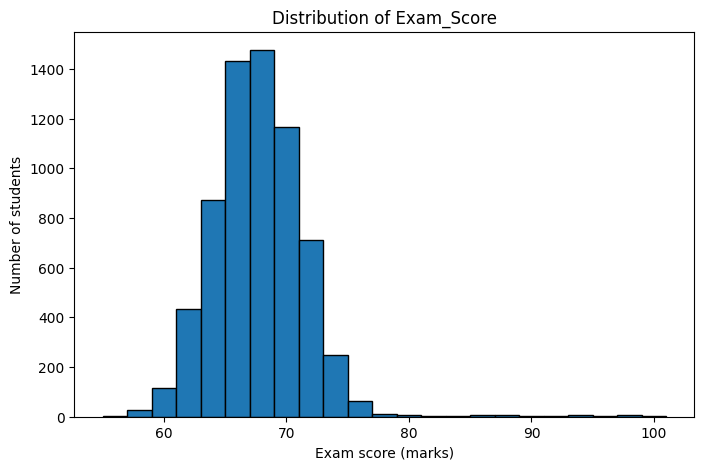

In [20]:
# 1. Histogram of the regression target
plt.figure(figsize=(8, 5))
plt.hist(df_clean['Exam_Score'], bins=range(55, 102, 2), edgecolor='black')
plt.title('Distribution of Exam_Score')
plt.xlabel('Exam score (marks)')
plt.ylabel('Number of students')
plt.savefig(out + 'hist_target.png', dpi=150, bbox_inches='tight')
plt.show()

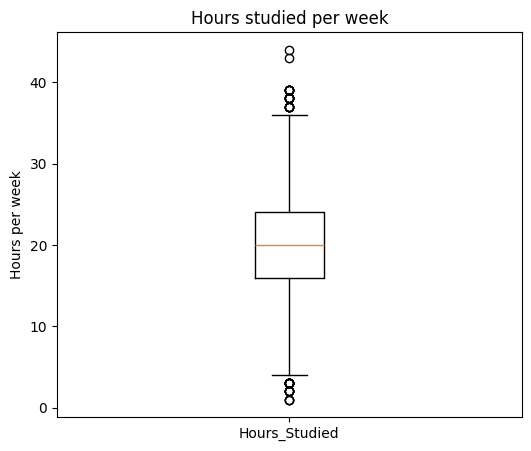

In [21]:
# 2. Box plot of one numeric feature (Hours_Studied)
plt.figure(figsize=(6, 5))
plt.boxplot(df_clean['Hours_Studied'])
plt.title('Hours studied per week')
plt.ylabel('Hours per week')
plt.xticks([1], ['Hours_Studied'])
plt.savefig(out + 'box_feature.png', dpi=150, bbox_inches='tight')
plt.show()

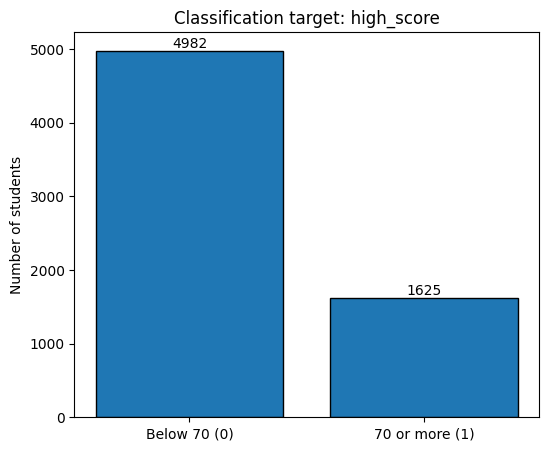

In [22]:
# 3. Bar chart of the classification target, with counts printed on the bars
counts = df_clean['high_score'].value_counts().sort_index()
plt.figure(figsize=(6, 5))
plt.bar(['Below 70 (0)', '70 or more (1)'], counts.values, edgecolor='black')
for i, v in enumerate(counts.values):
    plt.text(i, v + 40, str(v), ha='center')
plt.title('Classification target: high_score')
plt.ylabel('Number of students')
plt.savefig(out + 'bar_class.png', dpi=150, bbox_inches='tight')
plt.show()

Best predictor: effort 0.652


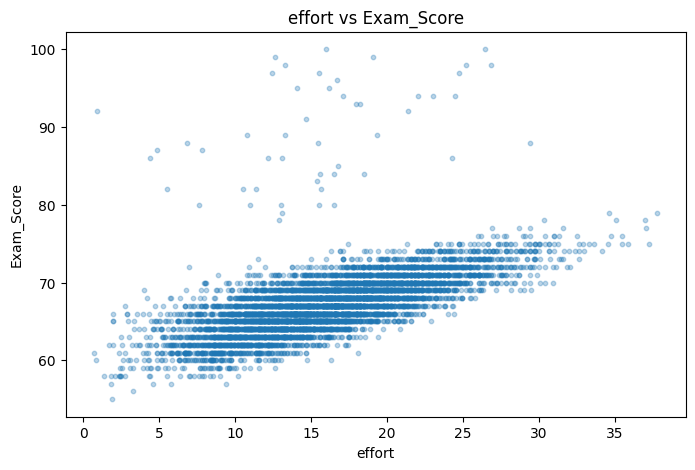

In [23]:
# 4. Scatter of the best numeric predictor against the target
# Let the data choose, and exclude high_score because it is built from Exam_Score (leakage)
corr = df_clean.corr()['Exam_Score'].drop(['Exam_Score', 'high_score'])
best = corr.idxmax()
print("Best predictor:", best, round(corr.max(), 3))

plt.figure(figsize=(8, 5))
plt.scatter(df_clean[best], df_clean['Exam_Score'], alpha=0.3, s=10)
plt.title(f'{best} vs Exam_Score')
plt.xlabel(best)
plt.ylabel('Exam_Score')
plt.savefig(out + 'scatter_best.png', dpi=150, bbox_inches='tight')
plt.show()

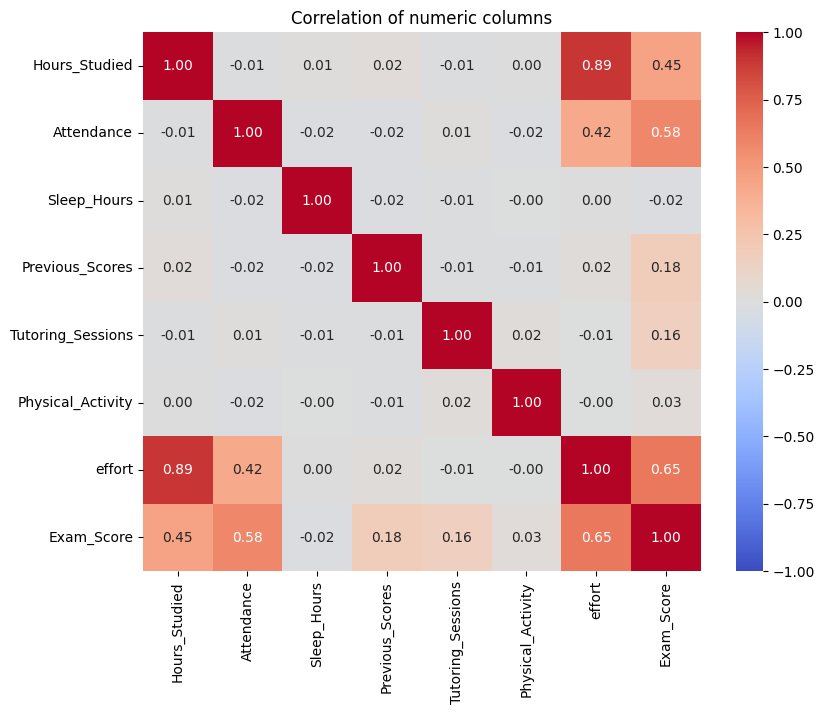

In [24]:
# 5. Correlation heatmap of the numeric columns
num_cols = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
            'Tutoring_Sessions', 'Physical_Activity', 'effort', 'Exam_Score']
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of numeric columns')
plt.savefig(out + 'corr_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### Feature Engineering, Outliers, and Data Validation Checks

**1. Feature Dependencies vs. Target Leakage (`effort` vs. `high_score`):**
- **`effort`:** Because `effort` is an engineered composite feature derived directly from `Hours_Studied` and `Attendance`, both source columns must already exist in the DataFrame before the calculation can run.
- **`high_score`:** Because `high_score` is our target variable (created directly from `Exam_Score >= 70`), keeping it—or `Exam_Score`—inside the input features (`X`) would cause **target leakage**, allowing the model to trivially cheat by seeing the answer during training rather than learning real predictors.

**2. Box Plot Outliers (`Hours_Studied`):**
- **Meaning of the Dots:** Each dot beyond the whiskers represents a statistical outlier flagged by the $1.5 \times \text{IQR}$ rule (values below $4$ or above $36$ hours per week, ranging from $1$ to $44$).
- **Reason for Retention:** These 43 records were retained because studying $1$ hour or $44$ hours per week is completely realistic for real students; dropping them would discard genuine behavioral variation rather than fix data errors.

**3. Catching Unmapped `NaN` Values:**
- If `.map()` encountered an unexpected category label and turned it into `NaN`, the **missing-value check** (`df.isnull().sum()`) in Cell 5 would immediately catch it by flagging a non-zero null count in that encoded column.

In [25]:
assert df_clean.isnull().sum().sum() == 0

In [26]:
# Import the two scalers
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Hours_Studied as a one-column table (scalers expect 2D input)
hours = df_clean[['Hours_Studied']]

# Demonstration only: scale the whole column both ways
minmax_vals = MinMaxScaler().fit_transform(hours)[:, 0]
standard_vals = StandardScaler().fit_transform(hours)[:, 0]

# Show the first five original, min-max and standardised values side by side
comparison = pd.DataFrame({'Original': hours['Hours_Studied'],
                           'MinMax': minmax_vals,
                           'Standard': standard_vals})
comparison.head(5).round(4)

,Original,MinMax,Standard
0,23,0.5116,0.5049
1,19,0.4186,-0.1628
2,24,0.5349,0.6719
3,29,0.6512,1.5066
4,19,0.4186,-0.1628


### Feature Scaling Strategy

**Min-Max Scaling (`[0, 1]` Range):** Rescales values linearly into a fixed $0$ to $1$ interval:
- **Best Suited For:** Algorithms that rely on bounded input ranges or distance calculations, such as neural networks and k-Nearest Neighbors (KNN).
- **Limitation:** Highly sensitive to extreme values; for example, retaining `Hours_Studied` up to `44` compresses the majority of typical student values into a narrow band near the bottom of the scale.

**Standard Scaling (Z-Score Normalization):** Centers features around a mean of $0$ with a standard deviation (spread) of $1$:
- **Best Suited For:** Linear and logistic regression, Support Vector Machines (SVM), and Principal Component Analysis (PCA), as it handles outliers more gracefully than Min-Max scaling.

**Tree-Based Models:** Algorithms such as Decision Trees, Random Forests, and Gradient Boosting make splits based on threshold ordering rather than feature magnitude or distance, meaning they require neither scaling method.

In [27]:
# Import the splitting tool
from sklearn.model_selection import train_test_split

# Features: everything except the regression target AND the target-derived high_score
X = df_clean.drop(columns=['Exam_Score', 'high_score'])
y = df_clean['Exam_Score']

# Split 80/20 with a fixed seed so everyone gets the same split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the scaler on the TRAINING set only (it learns each column's mean and std)
scaler = StandardScaler().fit(X_train)

# Apply the same learned numbers to both sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
# Self-check: sizes, no target in features, and the scaler learned from training data only
import numpy as np
assert X_train.shape == (5285, 22) and X_test.shape == (1322, 22)
assert 'Exam_Score' not in X.columns and 'high_score' not in X.columns
assert np.allclose(scaler.mean_, X_train.mean().values)
print("Split checks passed")

Split checks passed


### Key EDA Findings and Scaling Leakage Prevention

The most striking finding from the exploratory analysis is that our engineered `effort` feature ($r = 0.65$) correlates more strongly with `Exam_Score` than either of its individual components—`Attendance` ($r = 0.58$) or `Hours_Studied` ($r = 0.45$)—suggesting that combining study time and attendance captures student commitment better than either factor alone. Second, the target variable is noticeably imbalanced, with only 24.6% of students (1,625 out of 6,607) reaching the 70-mark threshold compared to 75.4% (4,982) scoring below it, so accuracy alone would be misleading for this target. Third, lifestyle habits like Sleep_Hours ($r = -0.02$) and Physical_Activity ($r = 0.03$) show virtually zero linear correlation with exam performance, indicating they contribute little linear predictive power on their own.